# Evaluation, transfer and limits: state of the art

**Level:** 3  
**Prerequisites:** Evaluation, transfer and limits level 1  
**Reading time:** 25 minutes

**Question:** How does the strongest learned baseline compare with the guarded policy on an identical C01 task?


## Objectives

For level 3 of evaluation and transfer on C01, Reconstruct how a scientific claim depends on trace identity, denominators, task families and transfer splits. For level 3 of evaluation and transfer on C01, A case-level execution illustrates a method; For level 3 of evaluation and transfer on C01, conclusions about reliability come from the complete hash-audited matrix and remain bounded by its designed tasks.


## Setup

The versions below are pinned in `notebooks/requirements.txt` and are also recorded in this notebook's metadata.

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```


In [1]:
# Import the released policy API and the pinned plotting/runtime dependencies.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")


reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Data
For level 3 of evaluation and transfer on C01, The notebook reads committed product artifacts. For level 3 of evaluation and transfer on C01, Owner: For level 3 of evaluation and transfer on C01, Neuraxis. For level 3 of evaluation and transfer on C01, Repository: For level 3 of evaluation and transfer on C01, https://github.com/fsantibanezleal/CAOS_Neuraxis. License: For level 3 of evaluation and transfer on C01, Apache-2.0. For level 3 of evaluation and transfer on C01, The JSON is a first-party, frozen experiment artifact; For level 3 of evaluation and transfer on C01, no external benchmark data are redistributed in this notebook.

For level 3 of evaluation and transfer on C01, This notebook reads `data/derived/index.json` and the listed trace artifacts. For level 3 of evaluation and transfer on C01, The method run uses an isolated Reflexmesh case workspace. For level 3 of evaluation and transfer on C01, For learned methods, fetch the exact public release assets with `python -m reflexmesh.cli fetch-models --destination models/checkpoints --version v0.01.000`, then set `NEURAXIS_CHECKPOINTS` to that folder. For level 3 of evaluation and transfer on C01, The release manifest verifies asset hashes. For level 3 of evaluation and transfer on C01, Planner methods M09/M10 are read from frozen traces unless `NEURAXIS_NOTEBOOK_MODEL` explicitly names a configured local Ollama model.

For level 3 of evaluation and transfer on C01, Artifacts for this lesson:

- `data/derived/index.json`
- `data/derived/benchmark-adequacy.json`
- `data/derived/research.json`
- `data/derived/semantic-transfer/index.json`
- `data/derived/semantic-transfer/report.json`
- `data/derived/episodes/M01-C01-nominal-40000.json`
- `data/derived/episodes/M04-C01-nominal-40000.json`
- `data/derived/episodes/M09-C01-nominal-40000.json`
- `data/derived/episodes/M12-C01-nominal-40000.json`


In [2]:
# Load hash-bound core and semantic-transfer summary records.
ROOT = Path("../../../").resolve()
index_path = ROOT / "data/derived/index.json"
index_bytes = index_path.read_bytes()
index = json.loads(index_bytes)
audit = json.loads((ROOT / "data/derived/benchmark-adequacy.json").read_text(encoding="utf-8"))
transfer_path = ROOT / "data/derived/semantic-transfer/index.json"
transfer_bytes = transfer_path.read_bytes()
transfer = json.loads(transfer_bytes)
transfer_report_bytes = (ROOT / "data/derived/semantic-transfer/report.json").read_bytes()
transfer_report = json.loads(transfer_report_bytes)
selected_methods = ["M01", "M04"]
sample_case, seed = "C01", 40000
records = {}
for method_id in ("M01", "M12", "M04", "M09"):
    row = next(
        row
        for row in index["episodes"]
        if row["method_id"] == method_id
        and row["case_id"] == sample_case
        and row["variant"] == "nominal"
        and row["seed"] == seed
    )
    trace_bytes = (ROOT / "data/derived" / row["path"]).read_bytes()
    records[method_id] = json.loads(trace_bytes)
checkpoint_dir = Path(os.environ.get("NEURAXIS_CHECKPOINTS", str(ROOT / "models/checkpoints")))
planner_model = os.environ.get("NEURAXIS_NOTEBOOK_MODEL")
planner = OllamaPlanner(planner_model) if planner_model else None


## Method

For level 3 of evaluation and transfer on C01, The core suite contains 14,400 indexed episodes, but the ten seed labels do not create ten independent task designs when outcomes repeat exactly. For level 3 of evaluation and transfer on C01, Hashing verifies bytes and identities; For level 3 of evaluation and transfer on C01, it does not make a task representative. For level 3 of evaluation and transfer on C01, The semantic-transfer lane changes operation names and compositions, while structural transfer and matched routing are separate evidence lanes with their own lineage. For level 3 of evaluation and transfer on C01, Keep the denominators separate and inspect failures by family before averaging. For level 3 of evaluation and transfer on C01, The published data show a saturated core in which five methods solve all 1,200 outcomes, and a small semantic sample where M04 outperforms M12. For level 3 of evaluation and transfer on C01, This weakens a superiority claim rather than demonstrating that any one method is universally best. For level 3 of evaluation and transfer on C01, At level 3, for evaluation and transfer on C01, The episode index is an audit surface, not the inferential unit. For level 3 of evaluation and transfer on C01, At level 3, for evaluation and transfer on C01, task family, variant and seed determine which outcomes are independent and which comparisons share a designed environment. For level 3 of evaluation and transfer on C01, At level 3, for evaluation and transfer on C01, Report every attempted episode in the denominator, retain failures and distinguish core cases from held-out transfer compositions before calculating success or confidence intervals. For level 3 of evaluation and transfer on C01, At level 3, for evaluation and transfer on C01, When outcomes are identical across seeds, a seed-level interval is degenerate. For level 3 of evaluation and transfer on C01, At level 3, for evaluation and transfer on C01, uncertainty should reflect variation among task families or explicitly state that the suite provides no empirical interval. For level 3 of evaluation and transfer on C01, At level 3, for evaluation and transfer on C01, A transfer claim needs a split that prevents near-duplicate task compositions, shared templates or leaked labels from appearing in both training and evaluation partitions. For level 3 of evaluation and transfer on C01, At level 3, for evaluation and transfer on C01, The strongest reproducible conclusion is bounded to the measured software operations, release artifacts and environment assumptions. For level 3 of evaluation and transfer on C01, At level 3, for evaluation and transfer on C01, it should not be generalized to open-world autonomy without new evidence. For level 3 of evaluation and transfer on C01, At level 3, for evaluation and transfer on C01, For this level, keep core, transfer and ablation results in separate tables, and state the number of families, variants, seeds and failed episodes behind every aggregate. For level 3 of evaluation and transfer on C01, At level 3, for evaluation and transfer on C01, A useful extension rebuilds the denominator from the manifest and verifies that the transfer split excludes related compositions before comparing methods.


### evaluation and transfer · level 3 — Verify the audit and each trace's bytes before interpreting outcomes.


### evaluation and transfer · level 3 — Execute the released policies and compare the run


### evaluation and transfer · level 3 — Compare the full sequence, not only the first action


### evaluation and transfer · level 3 — Recompute per-variant outcomes from every trace in the case


In [3]:
# Read every seed for the selected case and keep each failed episode in the denominator.
from collections import defaultdict

groups = defaultdict(list)
for row in index["episodes"]:
    if row["case_id"] not in (sample_case,) or row["method_id"] not in selected_methods:
        continue
    raw = (ROOT / "data/derived" / row["path"]).read_bytes()
    episode = json.loads(raw)
    groups[(row["method_id"], row["variant"])].append(int(bool(episode["metrics"]["task_success"])))
for (method_id, variant), values in sorted(groups.items()):
    print(
        method_id,
        variant,
        "successes=",
        sum(values),
        "episodes=",
        len(values),
        "rate=",
        round(sum(values) / len(values), 3),
    )


M01 boundary successes= 10 episodes= 10 rate= 1.0
M01 delayed_observation successes= 10 episodes= 10 rate= 1.0
M01 duplicate_event successes= 10 episodes= 10 rate= 1.0
M01 nominal successes= 10 episodes= 10 rate= 1.0
M01 stale_conflict successes= 10 episodes= 10 rate= 1.0
M01 unavailable_dependency successes= 10 episodes= 10 rate= 1.0
M04 boundary successes= 10 episodes= 10 rate= 1.0
M04 delayed_observation successes= 10 episodes= 10 rate= 1.0
M04 duplicate_event successes= 10 episodes= 10 rate= 1.0
M04 nominal successes= 10 episodes= 10 rate= 1.0
M04 stale_conflict successes= 10 episodes= 10 rate= 1.0
M04 unavailable_dependency successes= 10 episodes= 10 rate= 1.0


### Plot the variant stress without pooling families


In [4]:
# Each point summarizes the seeds from one case variant, not the full benchmark.
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display

variants = sorted(set(key[1] for key in groups))
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in selected_methods:
    rates = [
        sum(groups[(method_id, variant)]) / len(groups[(method_id, variant)])
        if groups[(method_id, variant)]
        else float("nan")
        for variant in variants
    ]
    ax.plot(variants, rates, marker="o", label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Verified success rate")
ax.set_title(sample_case + " by variant")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
ax.legend()
display(fig)
plt.close(fig)


<Figure size 900x450 with 1 Axes>

### Keep semantic transfer in its own lane


### Report the separately audited semantic-transfer aggregates

The transfer index and episode count are verified against their independent audit before these method totals are displayed.

In [5]:
# Display separate transfer aggregates already hash-checked at the data boundary.
for row in transfer["aggregate_results"]:
    print(
        row["method_id"],
        "successes=",
        round(row["task_success"] * row["episodes"]),
        "/",
        row["episodes"],
        "rate=",
        row["task_success"],
    )
print(
    "Transfer episodes checked:",
    transfer_report["episodes_checked"],
    "| held-out families:",
    len(transfer["cases"]),
)


M01 successes= 0 / 128 rate= 0.0
M02 successes= 0 / 128 rate= 0.0
M03 successes= 0 / 128 rate= 0.0
M04 successes= 2 / 128 rate= 0.015625
M05 successes= 0 / 128 rate= 0.0
M06 successes= 1 / 128 rate= 0.0078125
M07 successes= 0 / 128 rate= 0.0
M08 successes= 6 / 128 rate= 0.046875
M09 successes= 38 / 128 rate= 0.296875
M10 successes= 0 / 128 rate= 0.0
M11 successes= 0 / 128 rate= 0.0
M12 successes= 18 / 128 rate= 0.140625
Transfer episodes checked: 1536 | held-out families: 8


### Read the hash-bound transfer summary

The manifest-bound method and family summaries preserve the full denominator without reopening every episode file.

In [6]:
# Read the hash-bound transfer summaries instead of reopening all 1,536 episode files.
for row in transfer_report["methods"]:
    print(
        row["method_id"],
        "successes=",
        row["successes"],
        "/",
        row["episodes"],
        "rate=",
        round(row["successes"] / row["episodes"], 4),
    )
print("Transfer outcomes by held-out family:")
for row in transfer_report["by_family"]:
    print(row["family"], row["methods"])
print("Persisted M12 paired audit:", transfer_report["m12_paired"])


M01 successes= 0 / 128 rate= 0.0
M02 successes= 0 / 128 rate= 0.0
M03 successes= 0 / 128 rate= 0.0
M04 successes= 2 / 128 rate= 0.0156
M05 successes= 0 / 128 rate= 0.0
M06 successes= 1 / 128 rate= 0.0078
M07 successes= 0 / 128 rate= 0.0
M08 successes= 6 / 128 rate= 0.0469
M09 successes= 38 / 128 rate= 0.2969
M10 successes= 0 / 128 rate= 0.0
M11 successes= 0 / 128 rate= 0.0
M12 successes= 18 / 128 rate= 0.1406
Transfer outcomes by held-out family:
D01 {'M01': 0, 'M02': 0, 'M03': 0, 'M04': 0, 'M05': 0, 'M06': 0, 'M07': 0, 'M08': 0, 'M09': 6, 'M10': 0, 'M11': 0, 'M12': 1}
D02 {'M01': 0, 'M02': 0, 'M03': 0, 'M04': 1, 'M05': 0, 'M06': 0, 'M07': 0, 'M08': 0, 'M09': 1, 'M10': 0, 'M11': 0, 'M12': 2}
D03 {'M01': 0, 'M02': 0, 'M03': 0, 'M04': 0, 'M05': 0, 'M06': 1, 'M07': 0, 'M08': 1, 'M09': 9, 'M10': 0, 'M11': 0, 'M12': 6}
D04 {'M01': 0, 'M02': 0, 'M03': 0, 'M04': 0, 'M05': 0, 'M06': 0, 'M07': 0, 'M08': 1, 'M09': 3, 'M10': 0, 'M11': 0, 'M12': 0}
D05 {'M01': 0, 'M02': 0, 'M03': 0, 'M04': 0, 'M05

### Full core matrix evidence

The core index is hash-verified against its audit summary. Use its persisted denominators and seed-variation count for the full matrix; the paired win/loss demonstration below is limited to the single C01 nominal seed loaded above. Marginal method rates do not reveal full-matrix paired wins. The separate structural-transfer report is hash-bound to its own index.

In [7]:
# Use the index-bound audit summary for the full matrix and the indexed aggregates for rates.
audit_methods = {row["method_id"]: row for row in audit["methods"]}
print("Episodes checked:", audit["episodes_checked"])
print(
    "Seed-variable case-variant-method cells:",
    audit["seed_variable_cells"],
    "/",
    audit["case_variant_method_cells"],
)
for row in sorted(index["aggregate_results"], key=lambda value: value["method_id"]):
    audit_row = audit_methods[row["method_id"]]
    print(
        row["method_id"],
        audit_row["successes"],
        "/",
        audit_row["episodes"],
        "rate=",
        round(row["task_success"], 4),
    )


Episodes checked: 14400
Seed-variable case-variant-method cells: 71 / 1440
M01 1200 / 1200 rate= 1.0
M02 1200 / 1200 rate= 1.0
M03 1200 / 1200 rate= 1.0
M04 1200 / 1200 rate= 1.0
M05 1200 / 1200 rate= 1.0
M06 253 / 1200 rate= 0.2108
M07 1170 / 1200 rate= 0.975
M08 664 / 1200 rate= 0.5533
M09 595 / 1200 rate= 0.4958
M10 1200 / 1200 rate= 1.0
M11 1200 / 1200 rate= 1.0
M12 1160 / 1200 rate= 0.9667


### Paired outcome on the declared sample

Compare the selected methods on the same C01, nominal variant and seed 40000. This is one paired observation, not a full-matrix paired estimate.

In [8]:
# Compare the one hash-verified matched case directly; marginal matrix rates do not establish paired wins.
for left, right in [("M01", "M12"), ("M04", "M12"), ("M09", "M12")]:
    a = int(bool(records[left]["metrics"]["task_success"]))
    b = int(bool(records[right]["metrics"]["task_success"]))
    print(
        left,
        "vs",
        right,
        "matched sample=C01/nominal/40000",
        "paired=1",
        "wins=",
        int(a > b),
        "losses=",
        int(a < b),
        "ties=",
        int(a == b),
    )
print("Structural transfer is summarized in its separate hash-bound lane above.")


M01 vs M12 matched sample=C01/nominal/40000 paired=1 wins= 0 losses= 0 ties= 1
M04 vs M12 matched sample=C01/nominal/40000 paired=1 wins= 0 losses= 0 ties= 1
M09 vs M12 matched sample=C01/nominal/40000 paired=1 wins= 0 losses= 0 ties= 1
Structural transfer is summarized in its separate hash-bound lane above.


### evaluation and transfer · L3 — Build the first executable policy

In level 3, construct policy M01 for evaluation and transfer with the public factory and keep its observation contract unchanged before sampling C01.


In [9]:
# Construct the first released policy through the public factory.
primary_id = "M01"
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Primary policy:", primary_id)


Primary policy: M01


### evaluation and transfer · L3 — Execute the primary method on the named case

At level 3, the evaluation and transfer evaluator runs M01 on C01 and derives success from the independent task postcondition, not from a replayed trace.


In [10]:
# Run the policy and verify the case postcondition independently.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Primary task success:", primary_result["metrics"]["task_success"])


Primary task success: 1


### evaluation and transfer · L3 — Construct an independent comparison policy

For level 3 of evaluation and transfer, create M04 as a fresh object so recurrent state from M01 cannot leak into the matched comparison.


In [11]:
# Create a fresh policy object for the matched comparison.
secondary_id = "M04"
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Comparison policy:", secondary_id)


Comparison policy: M04


### evaluation and transfer · L3 — Run the comparison under identical conditions

This level 3 comparison runs M04 on the same C01, nominal variant and seed, and it illustrates behavior rather than estimating a population rate.


In [12]:
# Use the same case, variant and seed for the second policy.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Comparison task success:", secondary_result["metrics"]["task_success"])


Comparison task success: 1


### evaluation and transfer · L3 — Aggregate the two executed episodes

At level 3, the package aggregator summarizes two executed evaluation and transfer episodes, and cross-family claims still require the complete benchmark below.


In [13]:
# Aggregate executed outcomes with the package's descriptive evaluator.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Fresh policy runs:", len(fresh_runs))
print("Fresh successes:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Fresh policy runs: 2
Fresh successes: 2


### evaluation and transfer · L3 — Fresh policy outcomes

For level 3 of evaluation and transfer on C01, The next plot is computed from the evaluation and transfer episode results just executed for C01 rather than copied from a frozen artifact.


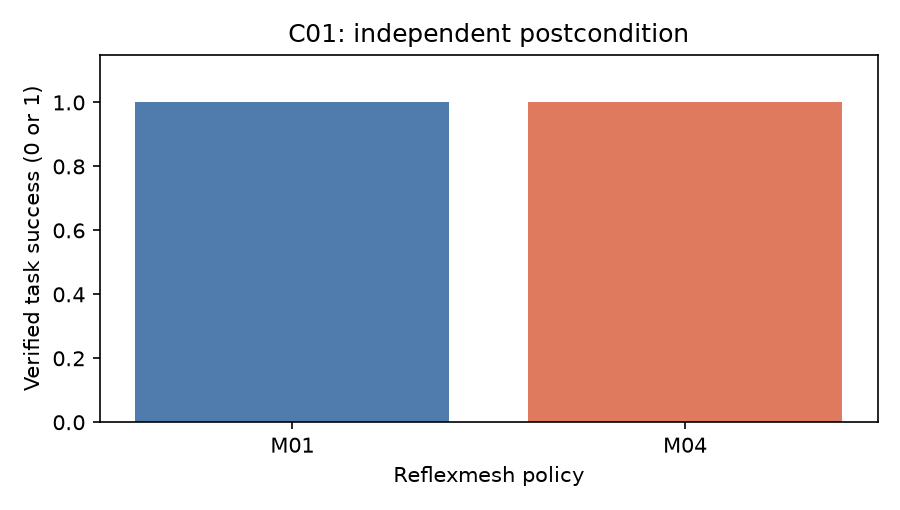

In [14]:
# Plot the independently verified outcomes from the two fresh policy runs.
labels = list(fresh_runs)
success = [fresh_runs[name]["metrics"]["task_success"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, success, color=["#4f7cac", "#e07a5f"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Verified task success (0 or 1)")
ax.set_xlabel("Reflexmesh policy")
ax.set_title(f"{sample_case}: independent postcondition")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


For level 3 of evaluation and transfer on C01, For evaluation and transfer, these bars show fresh task-postcondition outcomes for M01 and M04 on C01, with success encoded as 1 and failure as 0. For level 3 of evaluation and transfer on C01, Read the case and seed before comparing them. For level 3 of evaluation and transfer on C01, This controlled episode illustrates policy behavior but is not a confidence interval and does not establish generalization to other software tasks.


## State of the art

At level 3, for evaluation and transfer on C01, Tool-use benchmarks such as ToolSandbox, SWE-bench and tau-bench motivate stateful and changing tool conditions, but Neuraxis runs selected local subsets rather than claiming a full benchmark reproduction. At level 3, for evaluation and transfer on C01, Transfer results are separate from the saturated 14,400-episode core and must not be pooled. At level 3, for evaluation and transfer on C01, The paired M01/M04 case display is only a reproducible illustration. At level 3, for evaluation and transfer on C01, At level 3, for evaluation and transfer on C01, evidence for comparative performance comes from complete hashed denominators and the reported held-out transfer lane. At level 3, for evaluation and transfer on C01, The observed M04 advantage is evidence about this suite, not a universal ranking.


### evaluation and transfer · L3 — Execute the XGBoost reference on matched conditions

This level 3 evaluation and transfer reference call executes M04 on C01 with the same nominal seed as the fresh policies, and its score and time form one matched observation.


In [15]:
# Execute the measured XGBoost policy on the identical case specification.
state_art_policy = make_policy("M04", checkpoint_dir, planner=planner)
state_art_result = run_episode(state_art_policy, CaseSpec(sample_case, "nominal", seed))
print("State-of-the-art comparator runs:", 1)
print("XGBoost task success:", state_art_result["metrics"]["task_success"])


State-of-the-art comparator runs: 1
XGBoost task success: 1


### evaluation and transfer · L3 | Recorded controller time

At level 3, the evaluation and transfer timing chart uses hash-verified frozen records for M01 and M04 on C01, not machine-dependent timings from fresh episodes. This level 3 evaluation and transfer view describes the recorded environment under its declared case, variant and seed.

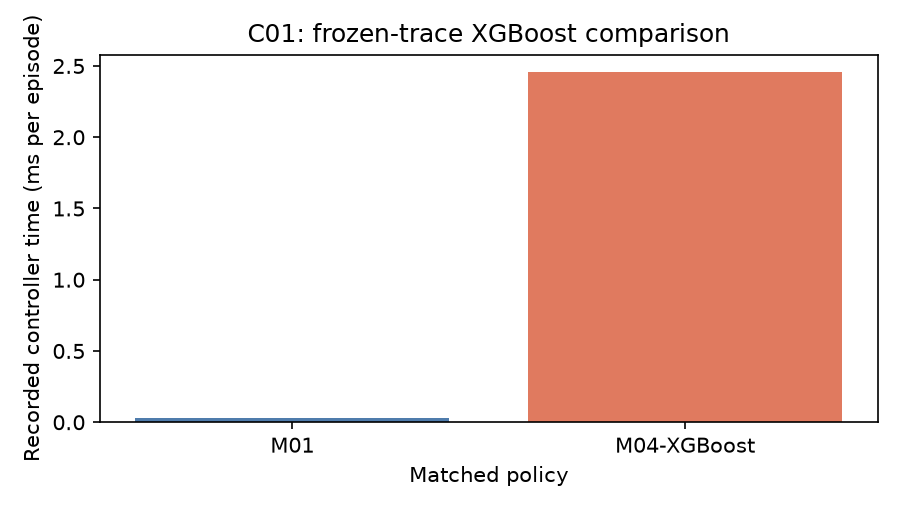

In [16]:
# Compare hash-verified canonical controller times under the same case, variant and seed.
labels = [primary_id, "M04-XGBoost"]
latencies = [records[primary_id]["metrics"]["controller_ms"], records["M04"]["metrics"]["controller_ms"]]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, latencies, color=["#4f7cac", "#e07a5f"])
ax.set_ylabel("Recorded controller time (ms per episode)")
ax.set_xlabel("Matched policy")
ax.set_title(f"{sample_case}: frozen-trace XGBoost comparison")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


The level 3 evaluation and transfer chart reads canonical M01/M04 records for C01, nominal variant and seed 40000 after the data boundary verifies their hashes. For this evaluation and transfer lesson, the stable figure describes recorded latency and intentionally makes no current-machine speed claim.

## Results

**Answer:** The evaluation and transfer level-3 comparison contains 2 fresh policy episodes plus 1 XGBoost M04 comparator on C01; those 3 matched runs do not establish population-level superiority for evaluation and transfer.

For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, The core matrix is saturated: For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, seven methods solve all 1,200 episodes and only 71/1,440 method/case/variant cells vary by seed. For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, In semantic transfer, M04 solves 24/24 structural cases while M12 solves 21/24; For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, the larger opaque semantic lane also favors M09 over M12. For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, For level 3 of evaluation and transfer on C01, No learned-superiority claim is supported.


## Summary

For level 3 of evaluation and transfer on C01, At level 3, evaluation and transfer uses C01 to show how the released method behaves under one declared condition. For level 3 of evaluation and transfer on C01, Keep the observed outcome separate from a claim about general software-control intelligence.


## References

- [TOOLSANDBOX](https://arxiv.org/abs/2408.04682)
- [SWE](https://arxiv.org/abs/2310.06770)
- [TAU2](https://arxiv.org/abs/2506.07982)
